# Random IV: multiscale im2spec + error model (offset-corrected patches)

- **Data:** topography image (`V3_IV_map_1d2um_0002.h5`) and IV curves at 2001 random grid points (`V3_IV_spec_1d2um_0003.h5`).
- **Offset:** the IV points are taken to sit at the recorded (row, col) + `OFFSET` on the image (see `obs.md`).
- **Patches:** 32×32 around each offset point. Patches that reach the image border are padded (image 0, mask 0).
- **Multiscale:** `pad` augmentation at scales 4, 8, 12, 16, 20, 24, 28 plus the full 32, with a validity-mask channel.
- **Training:** a single im2spec + error model on a fixed 10% training split (no active learning loop), then the
  3D error map, reduction over scales, and the next points from the distance acquisition function, as in the STM pipeline.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Rectangle
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset

STM_DIR = Path.cwd().parent / "STM"
if str(STM_DIR) not in sys.path:
    sys.path.insert(0, str(STM_DIR))
sys.argv = sys.argv[:1]  # the STM script parses its own flags only in main(); keep argv clean

# Reuse the STM pipeline pieces (normalization, mask model, error reduction, training).
import stm_ms_acqfn_script as stm  # also puts src/ on the path and registers the nnerror package
from stm_ms_acqfn_script import (Norm_G, spectra_errors, im2spec_mask, CustomDecoder_mask,
                                 reduce_errors_and_coords, find_row_indices, set_random_seed)
from nnerror.training_functions import train_model, predict_spectra, distance_acq_fn

from helper_fns import (load_random_iv, smooth_spectra, flatten_image, apply_offset,
                        get_padded_subimages, augment_with_mask)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Parameters

In [2]:
MAP_FILE = "content/V3_IV_map_1d2um_0002.h5"
SPEC_FILE = "content/V3_IV_spec_1d2um_0003.h5"

OFFSET = (-12, 7)        # (drow, dcol) added to the recorded IV positions; (0, 0) = no correction
WS = 32                  # patch size (largest scale)
SCALES = [4, 8, 12, 16, 20, 24, 28]   # smaller scales for 'pad' augmentation; the full WS patch is added as well
ALL_SCALES = SCALES + [WS]

train_size = 0.1
seed = 42
latent_dim = 5
n_epochs_im2spec = 100
n_epochs_error = 100
n_batches = 6
lr = 1e-3
patience = 10
use_swa = True
last_swa_epochs = 0.1
error_type = "L1"
num_new_points = 5

set_random_seed(seed)

## Load data

In [3]:
data = load_random_iv(MAP_FILE, SPEC_FILE)
topo, v_step = data["topo"], data["v_step"]
coords_recorded = data["coords"]
spectra_raw = data["iv"]
spectra = smooth_spectra(spectra_raw)          # Savitzky-Golay (55, 5), full 0 -> -2 -> 0 V sweep

coords = apply_offset(coords_recorded, OFFSET)  # image-grid (row, col) used for the patches
print(f"image {topo.shape}, spectra {spectra.shape}, points {len(coords)}")
print(f"recorded rows {coords_recorded[:, 0].min()}-{coords_recorded[:, 0].max()}, cols {coords_recorded[:, 1].min()}-{coords_recorded[:, 1].max()}")
print(f"offset   rows {coords[:, 0].min()}-{coords[:, 0].max()}, cols {coords[:, 1].min()}-{coords[:, 1].max()}")

image (128, 128), spectra (2001, 256), points 2001
recorded rows 15-113, cols 15-113
offset   rows 3-101, cols 22-120


## Image preparation and patch extraction

Plane (tilt) removed, then a global z-score (`Norm_G`, as in STM). Padded pixels are 0, which after the z-score is the image mean;
the mask channel tells the model they are not real.

In [4]:
image = Norm_G(data=flatten_image(topo)).normalize()
patches, border_masks = get_padded_subimages(image, coords, WS)
print("patches", patches.shape, "| masks", border_masks.shape)

# Check: the centre pixel of each patch is the image pixel at the offset coordinate.
assert np.allclose(patches[:, WS // 2, WS // 2], image[coords[:, 0], coords[:, 1]])

get_padded_subimages: 396 of 2001 patches reach the image border (padded, mask = 0)
patches (2001, 32, 32) | masks (2001, 32, 32)


### Where does the border padding matter?

At scale `s` the 'pad' augmentation keeps rows/cols `c - s/2 .. c + s/2 - 1` around the point. The image border only affects
that scale if this kept region crosses the border, i.e. if the point is closer than `s/2` px to the bottom/left edge or
closer than `s/2 - 1` px to the top/right edge. Image row 0 is a scan-start artifact (darker than the rest), so the count of
kept regions that include it is shown too.

In [5]:
H, W = image.shape
r, c = coords[:, 0], coords[:, 1]
print(f"distance to edges: bottom {r.min()} px, top {H - 1 - r.max()} px, left {c.min()} px, right {W - 1 - c.max()} px")
for s in ALL_SCALES:
    h = s // 2
    pads = (r - h < 0) | (r + h > H) | (c - h < 0) | (c + h > W)
    row0 = r - h <= 0
    print(f"scale {s:2d}: padding inside the kept region for {pads.sum():3d} points (rows < {h}); "
          f"kept region includes image row 0 for {row0.sum():3d} points (rows <= {h})")

distance to edges: bottom 3 px, top 26 px, left 22 px, right 7 px
scale  4: padding inside the kept region for   0 points (rows < 2); kept region includes image row 0 for   0 points (rows <= 2)
scale  8: padding inside the kept region for  24 points (rows < 4); kept region includes image row 0 for  44 points (rows <= 4)
scale 12: padding inside the kept region for  59 points (rows < 6); kept region includes image row 0 for  79 points (rows <= 6)
scale 16: padding inside the kept region for 105 points (rows < 8); kept region includes image row 0 for 127 points (rows <= 8)
scale 20: padding inside the kept region for 179 points (rows < 10); kept region includes image row 0 for 159 points (rows <= 10)
scale 24: padding inside the kept region for 253 points (rows < 12); kept region includes image row 0 for 198 points (rows <= 12)
scale 28: padding inside the kept region for 323 points (rows < 14); kept region includes image row 0 for 241 points (rows <= 14)
scale 32: padding inside the kep

## Visualize patch–spectrum pairs

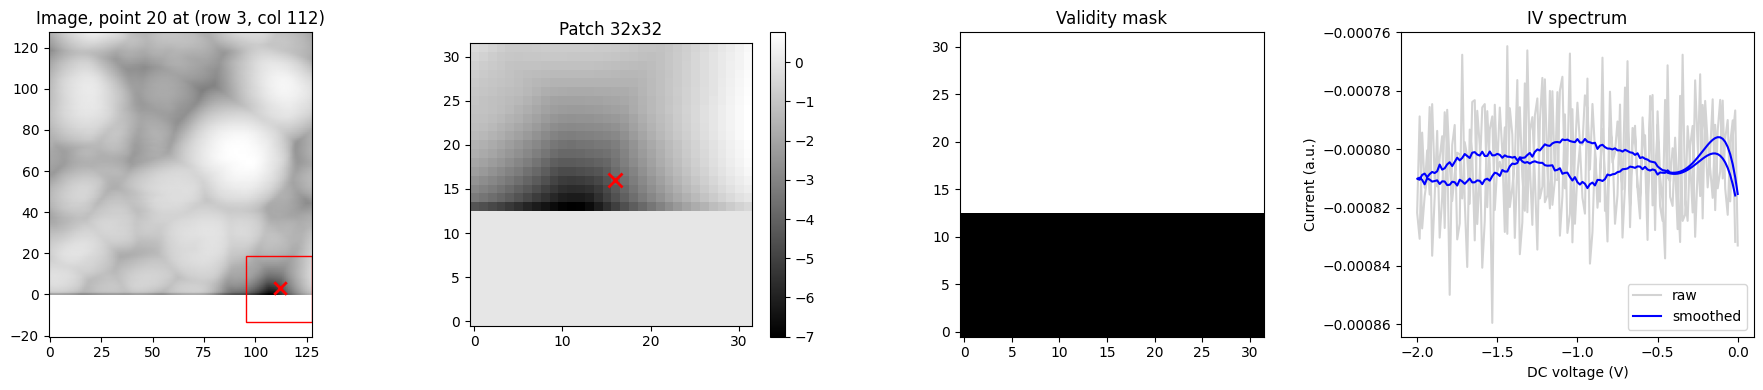

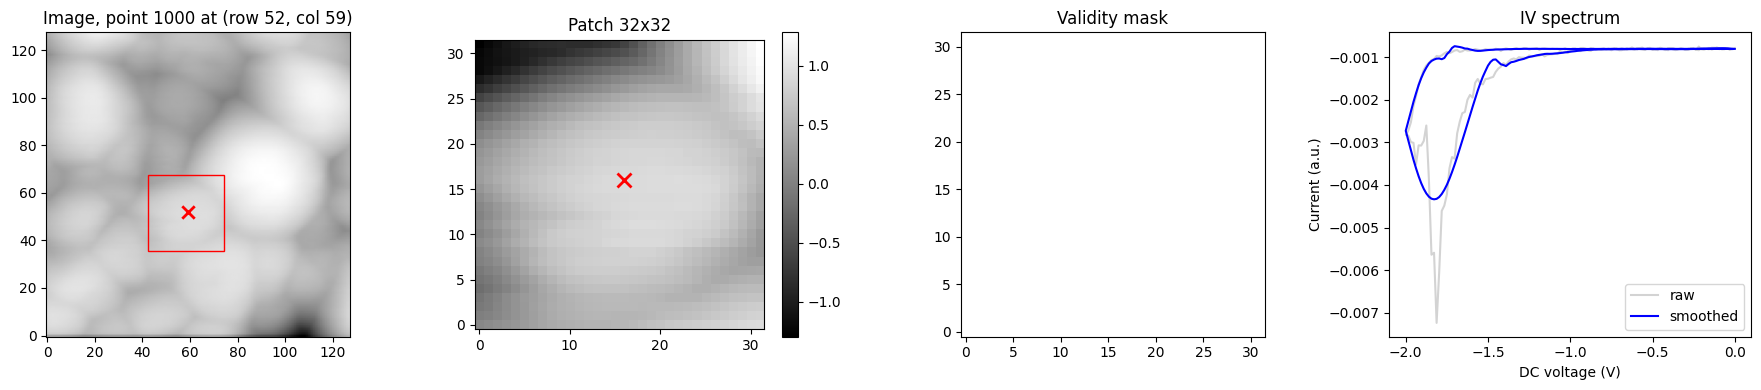

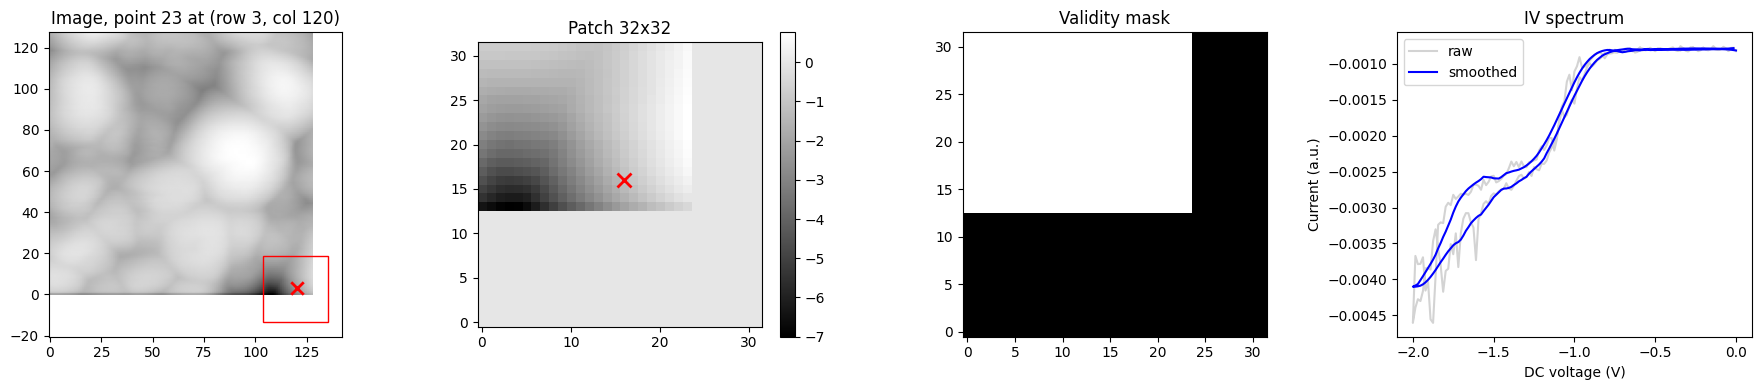

In [6]:
def show_pair(idx):
    r, c = coords[idx]
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(image, origin="lower", cmap="gray")
    ax[0].scatter(c, r, marker="x", c="r", s=80, linewidths=2)
    ax[0].add_patch(Rectangle((c - WS // 2 - 0.5, r - WS // 2 - 0.5), WS, WS, fill=False, ec="r", lw=1))
    ax[0].set_title(f"Image, point {idx} at (row {r}, col {c})")
    im = ax[1].imshow(patches[idx], origin="lower", cmap="gray")
    ax[1].plot(WS // 2, WS // 2, "rx", ms=10, mew=2)
    fig.colorbar(im, ax=ax[1]); ax[1].set_title(f"Patch {WS}x{WS}")
    ax[2].imshow(border_masks[idx], origin="lower", cmap="gray", vmin=0, vmax=1); ax[2].set_title("Validity mask")
    ax[3].plot(v_step, spectra_raw[idx], c="lightgray", label="raw")
    ax[3].plot(v_step, spectra[idx], c="b", label="smoothed")
    ax[3].set_xlabel("DC voltage (V)"); ax[3].set_ylabel("Current (a.u.)"); ax[3].legend(); ax[3].set_title("IV spectrum")
    plt.tight_layout(); plt.show()

border_idx = int(np.argmin(border_masks.mean((1, 2))))   # the point with the most padding
for idx in (20, 1000, border_idx):
    show_pair(idx)

## Train / test split (fixed 10%)

train 200, test 1801


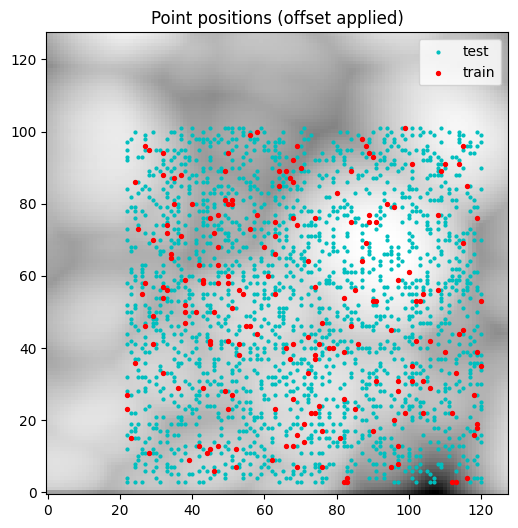

In [7]:
original_indices = np.arange(len(patches))
indices_train, indices_test = train_test_split(original_indices, train_size=train_size, random_state=seed)
print(f"train {len(indices_train)}, test {len(indices_test)}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(image, origin="lower", cmap="gray")
ax.scatter(coords[indices_test, 1], coords[indices_test, 0], s=4, c="c", label="test")
ax.scatter(coords[indices_train, 1], coords[indices_train, 0], s=8, c="r", label="train")
ax.legend(loc="upper right"); ax.set_title("Point positions (offset applied)")
plt.show()

## Multiscale augmentation (pad + mask)

Augmented images shape: (1600, 32, 32), Augmented spectra shape: (1600, 256), Augmented coordinates shape: (1600, 3)
Augmented images shape: (1600, 32, 32), Augmented spectra shape: (1600, 256), Augmented coordinates shape: (1600, 3)
Augmented images shape: (14408, 32, 32), Augmented spectra shape: (14408, 256), Augmented coordinates shape: (14408, 3)
Augmented images shape: (14408, 32, 32), Augmented spectra shape: (14408, 256), Augmented coordinates shape: (14408, 3)
Augmented images shape: (16008, 32, 32), Augmented spectra shape: (16008, 256), Augmented coordinates shape: (16008, 3)
Augmented images shape: (16008, 32, 32), Augmented spectra shape: (16008, 256), Augmented coordinates shape: (16008, 3)
train (1600, 2, 32, 32) | test (14408, 2, 32, 32) | all (16008, 2, 32, 32)


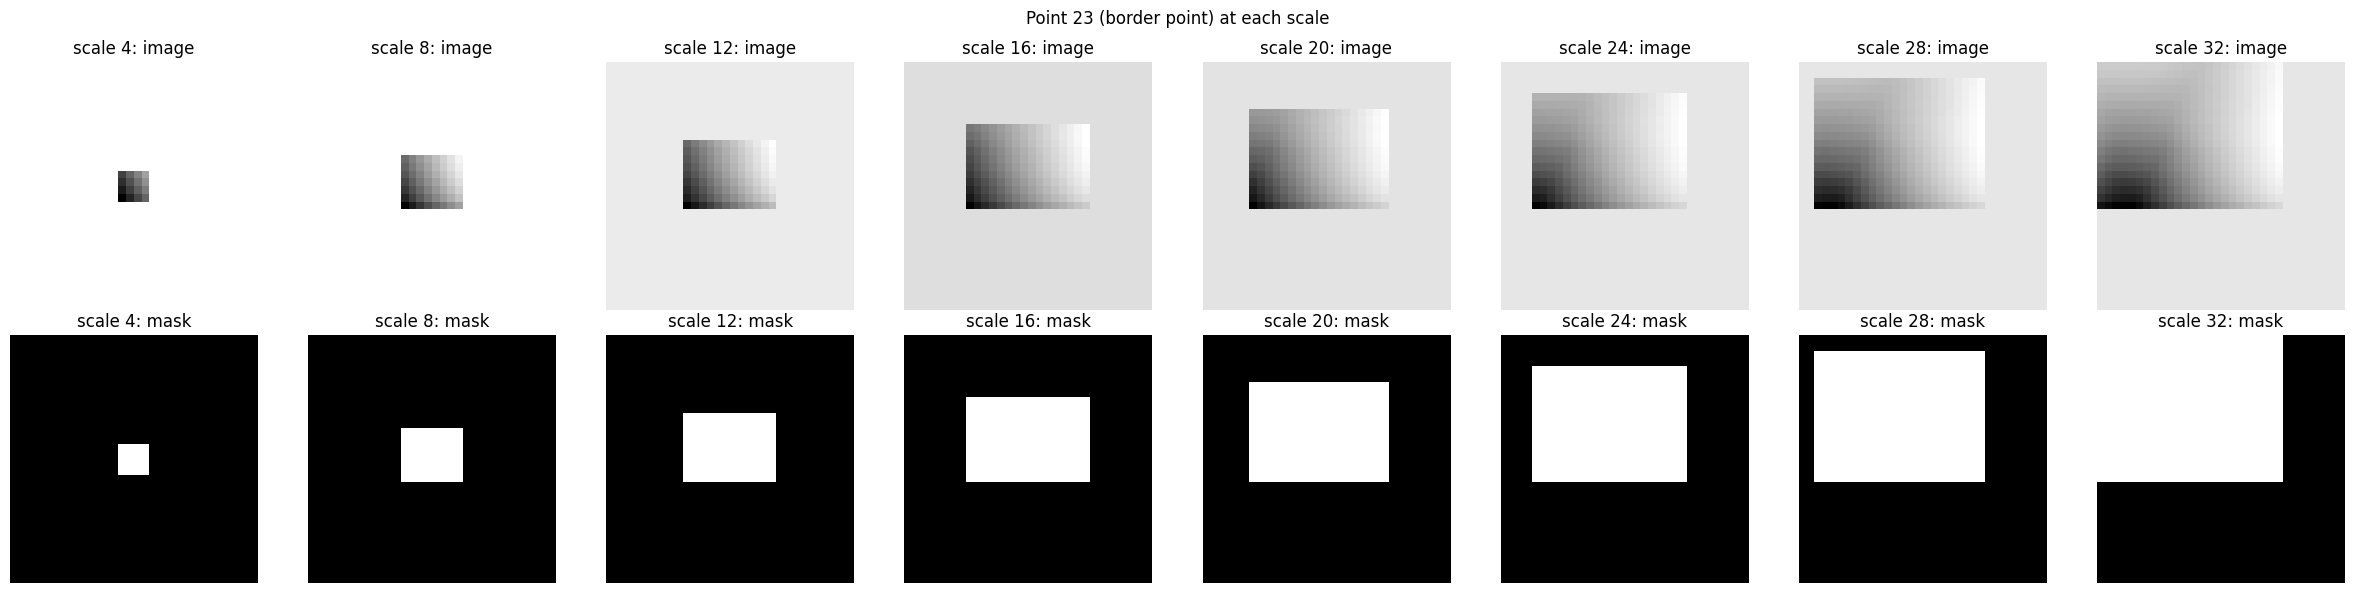

In [8]:
X_train, Y_train, C_train = augment_with_mask(indices_train, patches, border_masks, spectra, coords, SCALES)
X_test, Y_test, C_test = augment_with_mask(indices_test, patches, border_masks, spectra, coords, SCALES)
X_all, Y_all, C_all = augment_with_mask(original_indices, patches, border_masks, spectra, coords, SCALES)
print("train", X_train.shape, "| test", X_test.shape, "| all", X_all.shape)

k = border_idx
fig, ax = plt.subplots(2, len(ALL_SCALES), figsize=(3 * len(ALL_SCALES), 6))
for j, s in enumerate(ALL_SCALES):
    row = j * len(original_indices) + k            # blocks of N rows per scale
    assert C_all[row, 2] == s
    ax[0, j].imshow(X_all[row, 0], origin="lower", cmap="gray"); ax[0, j].set_title(f"scale {s}: image")
    ax[1, j].imshow(X_all[row, 1], origin="lower", cmap="gray", vmin=0, vmax=1); ax[1, j].set_title(f"scale {s}: mask")
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Point {k} (border point) at each scale"); plt.tight_layout(); plt.show()

## Train im2spec (2-channel input)

spectra Norm_G: mean -0.001596, std 0.001126


 91%|█████████ | 91/100 [00:42<00:03,  2.40it/s, train_loss=0.1431, val_loss=0.7390]

SWA triggered at epoch 90


100%|██████████| 100/100 [00:46<00:00,  2.16it/s, train_loss=0.1234, val_loss=0.8063]


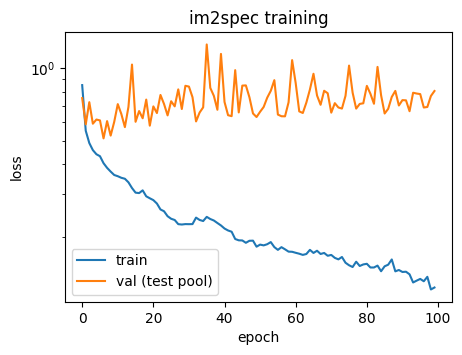

In [9]:
spec_norm = Norm_G(data=spectra[indices_train])   # global z-score, fitted on the training spectra
print(f"spectra Norm_G: mean {float(spec_norm.mean):.4g}, std {float(spec_norm.std):.4g}")

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(spec_norm.normalize(Y_train)))
val_ds = TensorDataset(torch.tensor(X_test), torch.tensor(spec_norm.normalize(Y_test)))

set_random_seed(seed)
im2spec_model = im2spec_mask(feature_size=(WS, WS), target_size=spectra.shape[1], latent_dim=latent_dim, in_channels=2).to(device)
im2spec_model, im2spec_train_loss, im2spec_val_loss = train_model(
    im2spec_model, train_ds, n_batches=n_batches, lr=lr, patience=patience, n_epochs=n_epochs_im2spec,
    partial_train=False, val_dataset=val_ds, use_swa=use_swa, last_swa_epochs=last_swa_epochs)

plt.figure(figsize=(5, 3.5))
plt.plot(im2spec_train_loss, label="train"); plt.plot(im2spec_val_loss, label="val (test pool)")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("im2spec training"); plt.show()

mean-spectrum baseline L1: 0.00052
  test L1 at scale  4: 0.00049
  test L1 at scale  8: 0.00051
  test L1 at scale 12: 0.00053
  test L1 at scale 16: 0.00055
  test L1 at scale 20: 0.00056
  test L1 at scale 24: 0.00056
  test L1 at scale 28: 0.00057
  test L1 at scale 32: 0.00057


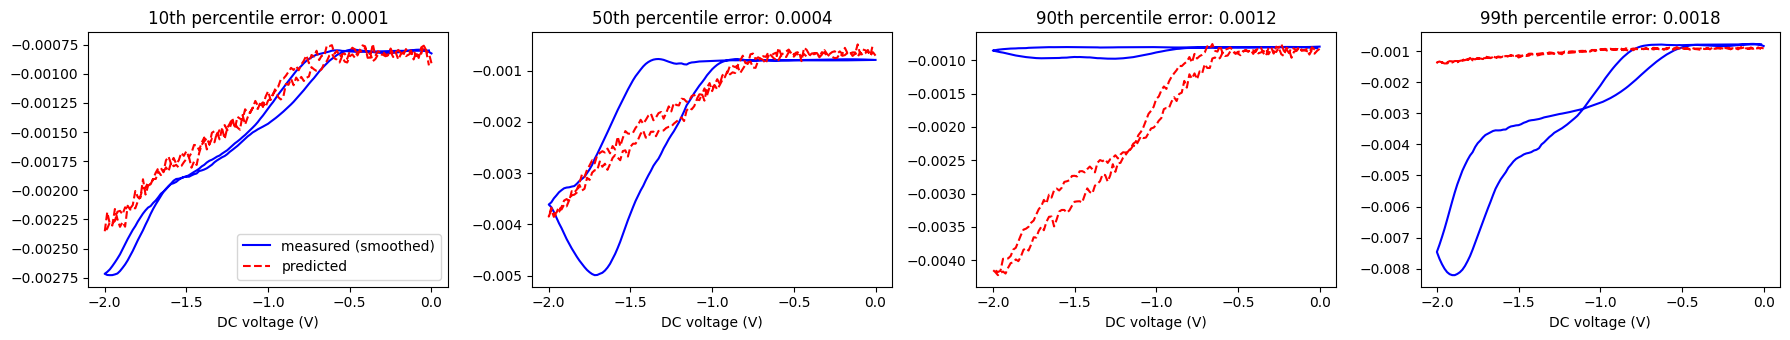

In [10]:
err_test = spectra_errors(im2spec_model, X_test, Y_test, spec_norm=spec_norm, error_type=error_type)
n_test = len(indices_test)
baseline = np.mean(np.abs(spectra[indices_test] - spectra[indices_train].mean(0)))
print(f"mean-spectrum baseline {error_type}: {baseline:.5f}")
for j, s in enumerate(ALL_SCALES):
    print(f"  test {error_type} at scale {s:2d}: {err_test[j * n_test:(j + 1) * n_test].mean():.5f}")

pred_test = spec_norm.denormalize(np.asarray(predict_spectra(im2spec_model, X_test, ensemble=False)).reshape(len(X_test), -1))
full = slice((len(ALL_SCALES) - 1) * n_test, len(ALL_SCALES) * n_test)   # full-scale block
order = np.argsort(err_test[full])
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, q in zip(ax, (0.1, 0.5, 0.9, 0.99)):
    i = order[int(q * (n_test - 1))]
    a.plot(v_step, Y_test[full][i], "b", label="measured (smoothed)")
    a.plot(v_step, pred_test[full][i], "r--", label="predicted")
    a.set_title(f"{int(q * 100)}th percentile error: {err_test[full][i]:.4f}"); a.set_xlabel("DC voltage (V)")
ax[0].legend(); plt.tight_layout(); plt.show()

## Error model (frozen im2spec encoder), as in STM

 92%|█████████▏| 92/100 [00:06<00:00, 12.57it/s, train_loss=0.3569, val_loss=0.3453]

SWA triggered at epoch 90


100%|██████████| 100/100 [00:07<00:00, 12.81it/s, train_loss=0.3527, val_loss=0.3325]


error model on test rows: corr(predicted, true) = -0.044


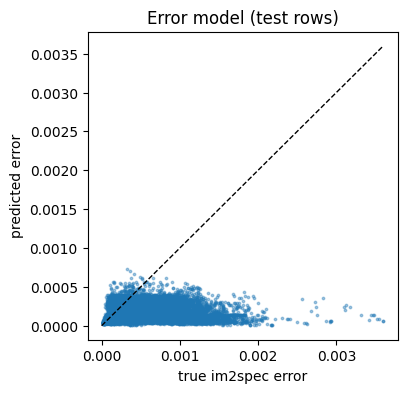

In [11]:
err_train = spectra_errors(im2spec_model, X_train, Y_train, spec_norm=spec_norm, error_type=error_type)
error_norm = Norm_G(data=err_train, log=True)     # z-score of log(error)
error_ds = TensorDataset(torch.tensor(X_train), torch.tensor(error_norm.normalize(err_train).reshape(-1, 1)))

with torch.no_grad():
    encoder_latent_dim = im2spec_model.encoder(torch.tensor(X_train[:1], device=device)).shape[1]

set_random_seed(seed)
error_model = CustomDecoder_mask(encoder=im2spec_model.encoder, embed_dim=encoder_latent_dim, target_size=1).to(device)
error_model, error_train_loss, _ = train_model(
    error_model, error_ds, n_batches=n_batches, lr=lr, patience=patience, n_epochs=n_epochs_error,
    partial_train=True, val_dataset=None, use_swa=use_swa, last_swa_epochs=last_swa_epochs)

pred_err_test = np.clip(error_norm.denormalize(predict_spectra(error_model, X_test, ensemble=False)).ravel(), 0, None)
print(f"error model on test rows: corr(predicted, true) = {np.corrcoef(pred_err_test, err_test)[0, 1]:.3f}")
plt.figure(figsize=(4, 4))
plt.scatter(err_test, pred_err_test, s=3, alpha=0.4)
lim = [0, max(err_test.max(), pred_err_test.max())]
plt.plot(lim, lim, "k--", lw=1); plt.xlabel("true im2spec error"); plt.ylabel("predicted error"); plt.title("Error model (test rows)")
plt.show()

## 3D error map, reduction over scales and next acquisition points

Predicted errors for all 2001 points at every scale form the 3D map (scale × point). `reduce_errors_and_coords` keeps the
minimum predicted error over scales for each point (and its scale), and `distance_acq_fn` picks the next points from the
test pool.

3D error map (scale x point): (8, 2001)


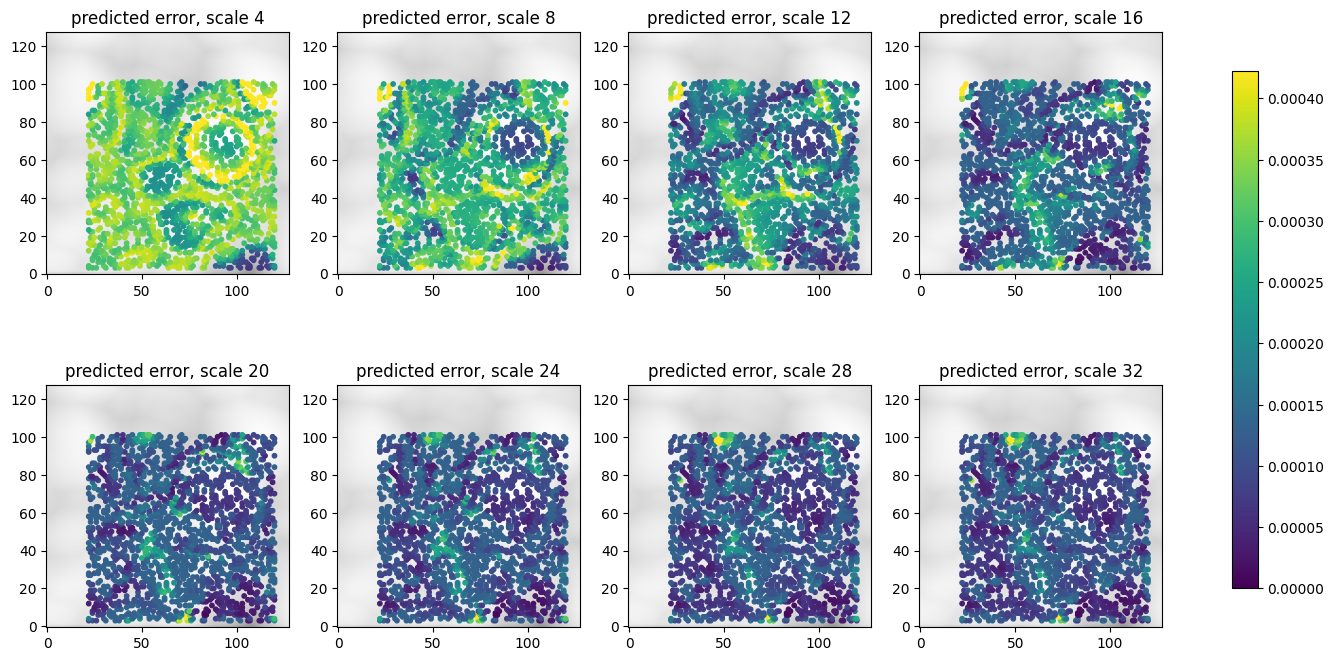

In [12]:
N = len(original_indices)
pred_err_all = np.clip(error_norm.denormalize(predict_spectra(error_model, X_all, ensemble=False)).ravel(), 0, None)
true_err_all = spectra_errors(im2spec_model, X_all, Y_all, spec_norm=spec_norm, error_type=error_type)
error_map_3d = pred_err_all.reshape(len(ALL_SCALES), N)     # [scale, point]
print("3D error map (scale x point):", error_map_3d.shape)

vmax = np.percentile(error_map_3d, 99)
ncol = 4
nrow = int(np.ceil(len(ALL_SCALES) / ncol))
fig, ax = plt.subplots(nrow, ncol, figsize=(4.5 * ncol, 4.2 * nrow), squeeze=False)
ax = ax.ravel()
for a in ax[len(ALL_SCALES):]:
    a.axis("off")
for j, s in enumerate(ALL_SCALES):
    ax[j].imshow(image, origin="lower", cmap="gray", alpha=0.4)
    sc = ax[j].scatter(coords[:, 1], coords[:, 0], c=error_map_3d[j], s=10, cmap="viridis", vmin=0, vmax=vmax)
    ax[j].set_title(f"predicted error, scale {s}")
fig.colorbar(sc, ax=ax.tolist(), shrink=0.8); plt.show()

In [13]:
reduced_errors, reduced_coords = reduce_errors_and_coords(pred_err_all, C_all, n_patches=N)
reduced_errors_im2spec = true_err_all[find_row_indices(C_all, reduced_coords)]
best_scale = reduced_coords[:, 2].astype(int)
assert np.array_equal(reduced_coords[:, :2].astype(int), coords)   # position i = point i

print("best-scale counts:", {s: int((best_scale == s).sum()) for s in ALL_SCALES})
print(f"mean reduced predicted error {reduced_errors.mean():.5f}; mean im2spec error at that scale {reduced_errors_im2spec.mean():.5f}")

aq_ind, aq_vals = distance_acq_fn(reduced_errors, beta=1, lambda_=1, sample_next_points=num_new_points,
                                  exclude_indices=indices_train.reshape(-1))
aq_ind = np.asarray(aq_ind, dtype=int).ravel()
assert not np.isin(aq_ind, indices_train).any()
print("next points to acquire:", aq_ind)
print("their image (row, col):", coords[aq_ind].tolist())
print("their recorded (row, col):", coords_recorded[aq_ind].tolist())

best-scale counts: {4: 7, 8: 26, 12: 89, 16: 440, 20: 314, 24: 200, 28: 377, 32: 548}
mean reduced predicted error 0.00009; mean im2spec error at that scale 0.00051
next points to acquire: [  56   11 1605 1991 1969]
their image (row, col): [[5, 73], [3, 74], [81, 107], [101, 54], [100, 54]]
their recorded (row, col): [[17, 66], [15, 67], [93, 100], [113, 47], [112, 47]]


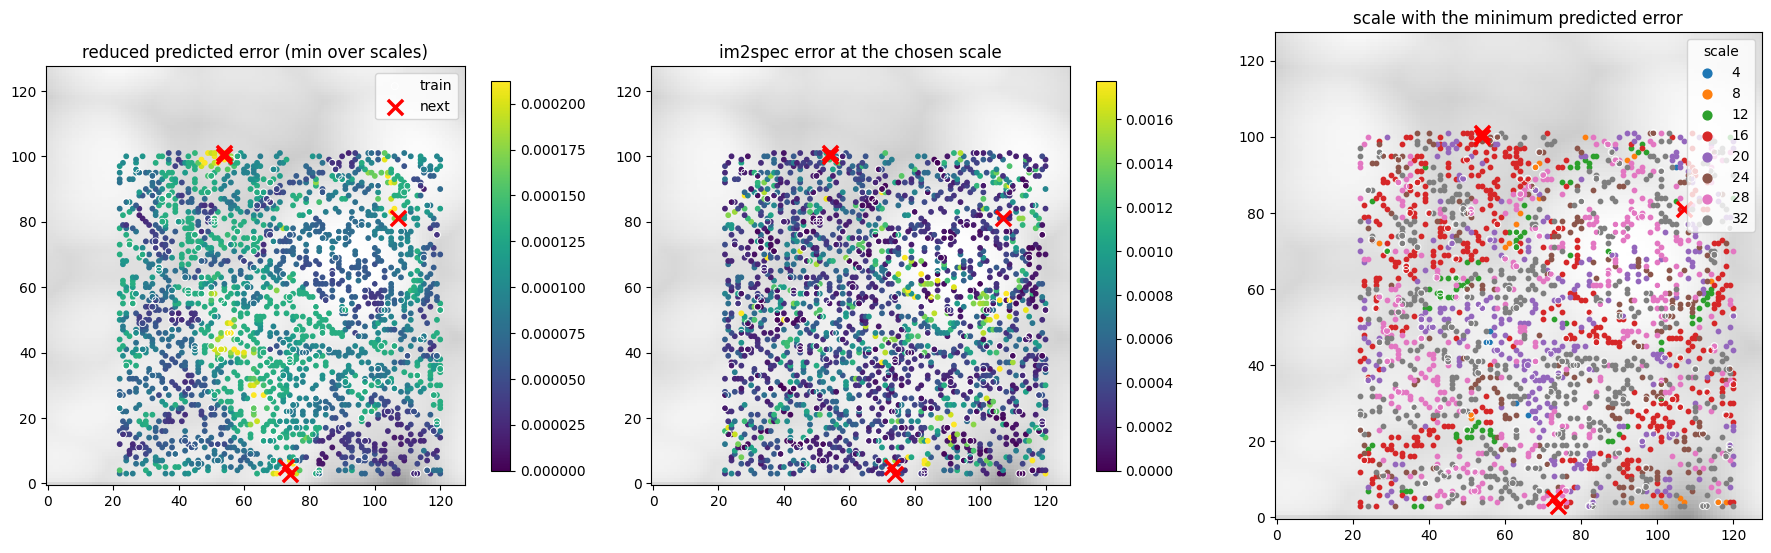

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, vals, title, cmap in ((ax[0], reduced_errors, "reduced predicted error (min over scales)", "viridis"),
                             (ax[1], reduced_errors_im2spec, "im2spec error at the chosen scale", "viridis"),
                             (ax[2], best_scale, "scale with the minimum predicted error", "tab10")):
    a.imshow(image, origin="lower", cmap="gray", alpha=0.4)
    if cmap == "tab10":
        for j, s in enumerate(ALL_SCALES):
            m = best_scale == s
            a.scatter(coords[m, 1], coords[m, 0], s=10, color=plt.cm.tab10(j), label=f"{s}")
        a.legend(title="scale", loc="upper right", markerscale=2)
    else:
        sc = a.scatter(coords[:, 1], coords[:, 0], c=vals, s=10, cmap=cmap, vmin=0, vmax=np.percentile(vals, 99))
        fig.colorbar(sc, ax=a, shrink=0.8)
    a.scatter(coords[indices_train, 1], coords[indices_train, 0], s=25, facecolors="none", edgecolors="w", lw=0.6, label="train")
    a.scatter(coords[aq_ind, 1], coords[aq_ind, 0], marker="x", c="r", s=120, linewidths=2.5, label="next")
    a.set_title(title)
ax[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

## Interactive 3D error map

x = col, y = row, z = scale. Drag to rotate, scroll to zoom, hover for values. The dropdown switches between the error model's
predicted error and the true im2spec error. Red diamonds: next points to acquire, at their chosen scale; gray vertical lines: training
points (through all scales). The same page is saved as `error_3d.html` (open it in a browser).

In [16]:
from helper_fns import error_3d_html, show_html_iframe

html = error_3d_html(
    coords, ALL_SCALES,
    {"predicted error": error_map_3d, "true im2spec error": true_err_all.reshape(len(ALL_SCALES), N)},
    highlight={"train": (indices_train, None, "lightgray", "circle"),
               "next points": (aq_ind, best_scale[aq_ind], "red", "diamond")},
    title=f"Random IV {error_type} error per scale (offset {OFFSET})")
Path("error_3d.html").write_text(html)
show_html_iframe(html)